# Runnables

## why we need runnable

2022 mai chatgpt realease hua to lanchain develop hua or usme ek esa interface bnaya gya jisse hm kisi bi company(openai,anthroopic,google) ke api call kr skte with minimal changes 

then langchain team ne decide kiya ki hm ds llm se baat krne pe ni focus krenege baki aspects pe b foucs krnege

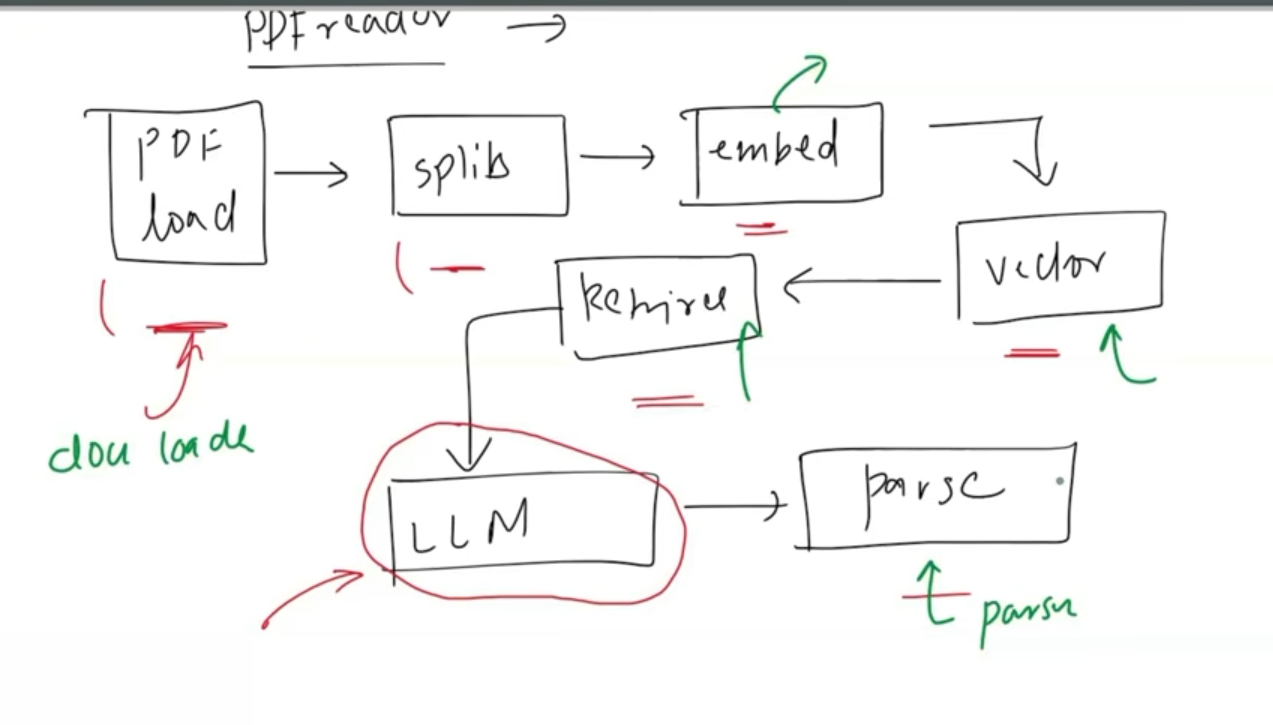

1. dataload-> document loader
2. splits-> text splitter
3. embedding ke liye component
4. retrivers, vector database, parser ese components bnaye taaki developer lyi llm based application bnana asan hoje

In [ ]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_community.vectorstores import FAISS
from langchain_ollama import ChatOllama

# Load the document
loader = TextLoader("docs.txt")
documents = loader.load()

# Split text into smaller chunks
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

docs = text_splitter.split_documents(documents)

# Convert text into embeddings and store in FAISS
vectorstore = FAISS.from_documents(
    docs,
    OpenAIEmbeddings()
)

# Create a retriever
retriever = vectorstore.as_retriever()

# Retrieve relevant documents
query = "What are the key takeaways from the document?"
retrieved_docs = retriever.invoke(query)

# Combine retrieved text
retrieved_text = "\n".join(
    doc.page_content for doc in retrieved_docs
)

# Initialize the chat model
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)

# Pass retrieved text to the model
prompt = f"""Based on the following text, answer the question.

Question: {query}

Context:
{retrieved_text}
"""

answer = model.invoke(prompt)

# Print the answer
print(answer.content)

abhi code ni smjhna abi bs yeh dekh langchain ke components bnane se hmare liye development kitni asaan hogyi

hun dekh asi components saare connect kr rhe te llms bna rhe hun langchain develops ne notice kita koi vi llm application bnande kuch steps common hai jive prompt bnana te llm appilication nu dena eh step hr llm vich hunda hi hai

hle tk ai engineer sara kaam manually kr rhe si phele PromptTemplate to template bnaya fir template to prompt bnana fir prompt nu llm kol bhjna output receive krne lyi

Template(prompttemplate)-> prompt -> llm->output

lanchain develop ne eh kaam automate krne lyi chains bna ti jo apa pdhi hai joki eh pura step bht simple kr dindi hai

one of common chain is llmchain

### llmchain

In [ ]:
from langchain_openai import ChatOpenAI
from langchain.chains import LLMChain
from langchain_core.prompts import PromptTemplate

# Load the LLM (GPT model)
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.7)

# Create a Prompt Template
prompt = PromptTemplate(
    input_variables=["topic"],
    template="Suggest a catchy blog title about {topic}."
)

# Create an LLMChain
chain = LLMChain(llm=llm, prompt=prompt)

# Run the chain with a specific topic
topic = input("Enter a topic: ")
output = chain.run(topic)

print("Generated Blog Title:", output)

langchain develops ne dekhya ki eh kaam chain wala vadiya hai eda de bht task hunde hai jihna nu asan kita ja skda hai
jive rag based application(pdf reader) vich retreiver use hunda hi hunda hai 

retreiver hunda hai jive user ne ek query diti hun us query de related asi data chunk dhunda ge in vector database

rag based application vich ki hunda hai dekh

user ne diti query fir us query de basic te asi chunk nikalde haa vector database vich jo query de related hai hun related text aagya hun asi llm nu apni query te related text dinde haaa to find our output

ehnu vi automate krni di koshish kiti jisme bs llm or retreiver btana hai (retriverQa chain)


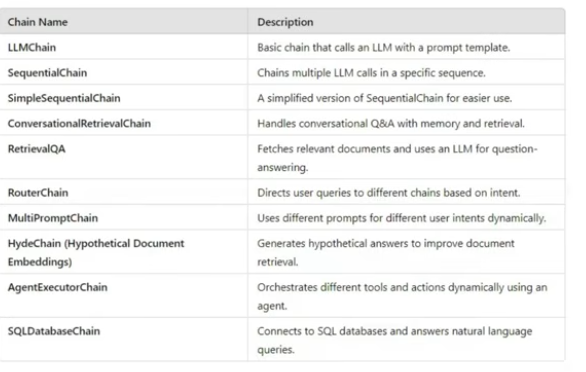

eh sab chains hai jo langchain developers ne bna ti on basis of different use case

#### problems with chain

* code base too big because of many chains(bda codebase maintain krna mushkil hunda hai)
* nye AI Engineers nu pta nahi lg reha si ki kehda kd use krna chain

hun dekh jo prompts,model etc jo vi components hai langchain de oh saare standadized ni hai mtlb saare independently develop kite gye hai hr ek da apna apna function hai hun jd 2 components integrate krne si ta custom code likhna painda si kunki dono components independent hai is lyi bht jyada custom code likhna painda si jihde krke code base heavy hogya ta lanchain developers nu smjh aagya ohna nu components dobara design krne paine ek standard rkh kr eh possible hoya with runnables

## What are runnable

characterstics
* runnable can be consider as a unit of work that can receive a input process it and can produce output
* Common interface saare runnables same functions use krde hai (eg invoke,batch(),stream()) batch generally input lenda hai in abatch fir output dinda hai
* easy to connect multiple runnables r1 r2 hai ta r1 da output r2 lyi input bn jayega




(r1->r2->r3) eh vi ek runnable hai

(r3-r4) eh vi ek runnable hai te upr wwaale naal jod skde


In [1]:
import random
class nakliLLM:
    def __init__(self):
        print('LLM created')

    def predict(self,prompt):
        response_list=[
            "Delhi is capital of india",
            "ipl is a cricket league",
            "AI stands for artificial intelligence"

        ]
        return {'response':random.choice(response_list)}



In [2]:
llm=nakliLLM()

LLM created


In [3]:
llm.predict('abc')

{'response': 'AI stands for artificial intelligence'}

In [4]:
class nakliPrompt:
    def __init__(self,template,input_variables):
        self.template=template
        self.input_variables=input_variables

    def format(self,input_dict):
        return self.template.format(**input_dict)



In [5]:
template=nakliPrompt(
    template='write a note on {topic}',
    input_variables=['topic']
)
prompt=template.format({'topic':'cricket'})

In [6]:
llm=nakliLLM()

LLM created


In [7]:
llm.predict(prompt)

{'response': 'ipl is a cricket league'}

In [8]:
class NakliLLMChain:

  def __init__(self, llm, prompt):
    self.llm = llm
    self.prompt = prompt

  def run(self, input_dict):

    final_prompt = self.prompt.format(input_dict)
    result = self.llm.predict(final_prompt)

    return result['response']


In [9]:
template = nakliPrompt(
    template='Write a {length} poem about {topic}',
    input_variables=['length', 'topic']
)

In [10]:
llm = nakliLLM()

LLM created


In [11]:
chain = NakliLLMChain(llm, template)

In [12]:
chain.run({'length':'short', 'topic': 'india'})

'Delhi is capital of india'

runnable standardize kr dinda hai saare component nu dusra code video 8 de description vich hai mai likhya ni hun ede vich ek runnable abstract class bna ti te ohde vich ek abstract method bnata invoke naam da hun llm nu use krn lyi asi predict use kr rhe si te prompt use krn lyi format hun llm te prompt nu runnable class inherit krwai jo abstract method hai invoke oh function llm te prompt dona vich bnaya te saara kaam standize krta ek function naam te predict te format ni use krne paine 

predict te format use krne te warning dedo these methods will be depricated use invoke function eh example hai sequence runnable da jihde vich kine vi runnables asi jod skde in a sequence te hr ek da output agle lyi input bn jana 